In [9]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt


definitions:

AC Power unit = kilowatts (kW)

In [3]:
#plant 1 generation eda 
files = {
    "plant_1_generation": ("Plant_1_Generation_Data.csv", "generation"),
    "plant_1_weather": ("Plant_1_Weather_Sensor_Data.csv", "weather"),
    "plant_2_generation": ("Plant_2_Generation_Data.csv", "generation"),
    "plant_2_weather": ("Plant_2_Weather_Sensor_Data.csv", "weather"),
}
df = pd.read_csv(Path.cwd() / "data" / "raw" / files["plant_1_generation"][0])

In [4]:
df['AC_POWER'].describe()

count    68778.000000
mean       307.802752
std        394.396439
min          0.000000
25%          0.000000
50%         41.493750
75%        623.618750
max       1410.950000
Name: AC_POWER, dtype: float64

This shows the mean is much higher than the median (50%) potentially being right skewed. The standard deviation is also very high at 394.
Range: 0 to 1,410.95
Next questions: Are zero power readings valid, and what is the timestamps of those readings, eg could the be reflecting nighttime readings?

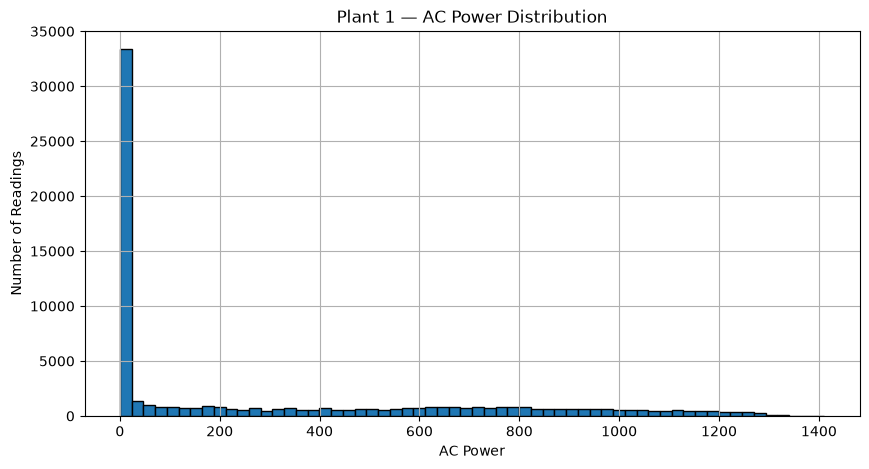

In [6]:
plt.figure(figsize=(10, 5))

df["AC_POWER"].hist(
    bins=60,
    edgecolor="black"
)

plt.title("Plant 1 — AC Power Distribution")
plt.xlabel("AC Power")
plt.ylabel("Number of Readings")
plt.show()

This confirms right skew of AC Power measured in kW

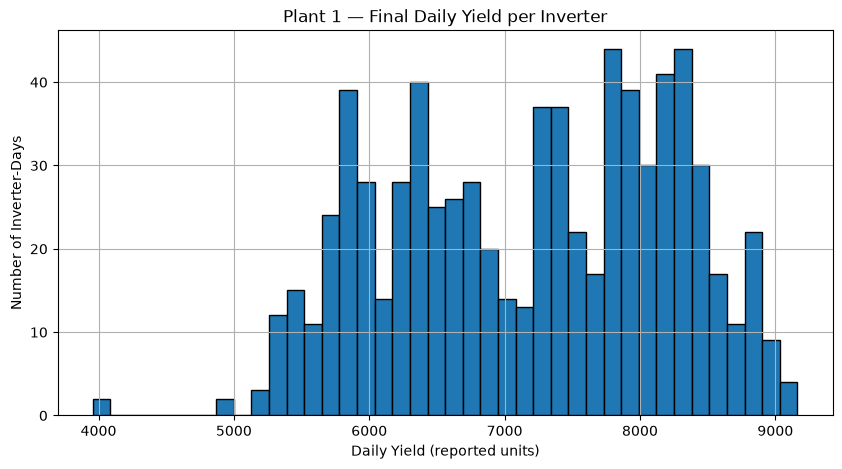

In [ ]:
#extract date
df["DATE_TIME"] = pd.to_datetime(
    df["DATE_TIME"],
    format="mixed",
    dayfirst=True
)

df["DATE"] = df["DATE_TIME"].dt.date

#group by inverter and date to find max daily yield per inverter
daily_yields = (
    df.groupby(["SOURCE_KEY", "DATE"])["DAILY_YIELD"]
    .max()
)

daily_yields.hist(
    bins=40,
    edgecolor="black",
    figsize=(10, 5)
)

plt.title("Plant 1 — Final Daily Yield per Inverter")
plt.xlabel("Daily Yield (reported units)")
plt.ylabel("Number of Inverter-Days")
plt.show()

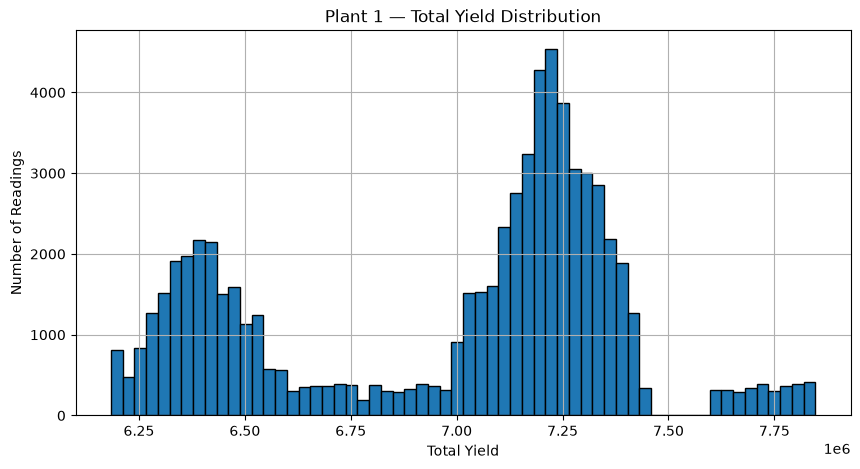

In [30]:
#find distribution of total yield 
plt.figure(figsize=(10, 5))

df["TOTAL_YIELD"].hist(
    bins=60,
    edgecolor="black"
)

plt.title("Plant 1 — Total Yield Distribution")
plt.xlabel("Total Yield")
plt.ylabel("Number of Readings")
plt.show()

In [ ]:
#find all zero readings

df["DATE_TIME"] = pd.to_datetime(
    df["DATE_TIME"],
    #make sure pandas can read different date formats, as a precaution 
    format="mixed",
    dayfirst=True
)
zero_readings = df[df["AC_POWER"] == 0]

zero_readings[
    ["DATE_TIME", "SOURCE_KEY", "AC_POWER"]
].head(10)



,DATE_TIME,SOURCE_KEY,AC_POWER
0,2020-05-15,1BY6WEcLGh8j5v7,0.0
1,2020-05-15,1IF53ai7Xc0U56Y,0.0
2,2020-05-15,3PZuoBAID5Wc2HD,0.0
3,2020-05-15,7JYdWkrLSPkdwr4,0.0
4,2020-05-15,McdE0feGgRqW7Ca,0.0
5,2020-05-15,VHMLBKoKgIrUVDU,0.0
6,2020-05-15,WRmjgnKYAwPKWDb,0.0
7,2020-05-15,ZnxXDlPa8U1GXgE,0.0
8,2020-05-15,ZoEaEvLYb1n2sOq,0.0
9,2020-05-15,adLQvlD726eNBSB,0.0


In [16]:
#find count of zero readings
len(zero_readings)

31951

In [22]:
#group zero readings by date 
#extract hour at each ts, group records by hour
zero_readings_grouped =zero_readings.groupby(zero_readings["DATE_TIME"].dt.hour).size() 
#sort by the highest number of records with zero readings, using sort index to sort by hour of the day
print(zero_readings_grouped.sort_index(ascending=False).head(10))

DATE_TIME
23    2750
22    2948
21    2962
20    2924
19    2669
18     903
15       1
14       6
13      27
12      19
dtype: int64


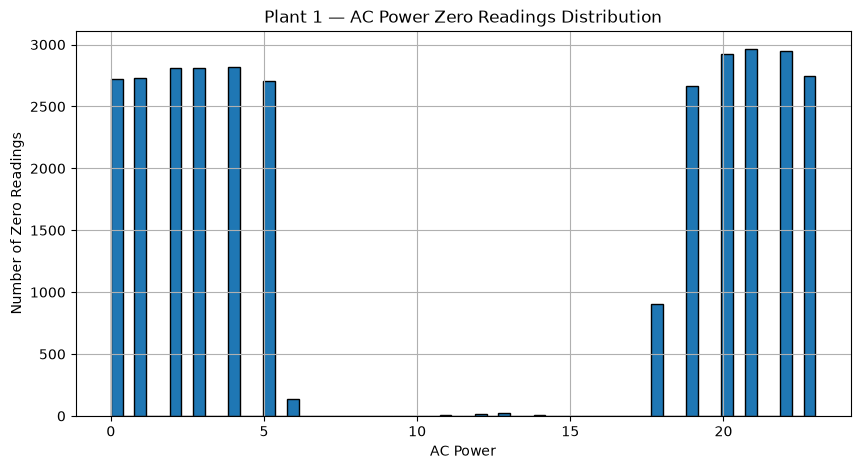

In [24]:
#find distribution of zero readings
plt.figure(figsize=(10, 5))

zero_readings["DATE_TIME"].dt.hour.hist(
    bins=60,
    edgecolor="black"
)

plt.title("Plant 1 — AC Power Zero Readings Distribution")
plt.xlabel("AC Power")
plt.ylabel("Number of Zero Readings")
plt.show()

In [ ]:
#find percentage of zero readings 
nighttime_zeros = zero_readings[
    #accounts for after 7pm and before 6am
    (zero_readings["DATE_TIME"].dt.hour >= 19) |
    (zero_readings["DATE_TIME"].dt.hour < 6)
]

nighttime_percentage = len(nighttime_zeros) / len(zero_readings) * 100

print(f"Percentage of zero readings occurring at night: {nighttime_percentage:.2f}%")

Percentage of zero readings occurring at night: 96.54%


Visual of zero readings and nightime percentage of zero readings confirms these are probably correct. 